# spatial neighbourhoods

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.neighbors import radius_neighbors_graph
import scanpy as sc

def spatial_neighbourhoods_fast(
    ad,
    cluster_label="leiden_0.5",
    max_distance=200.0,
    x_col="x_centroid",
    y_col="y_centroid",
):
    """
    Returns an AnnData where X is (cells x clusters) with counts of neighbors
    within `max_distance` per cluster. Uses sparse ops (fast + memory-light).
    """
    # --- coordinates ---
    coords = ad.obs[[x_col, y_col]].to_numpy()

    # Sparse adjacency (N x N) with 1 if within radius, excluding self
    A = radius_neighbors_graph(
        coords, radius=max_distance, mode="connectivity",
        include_self=False, n_jobs=-1
    ).tocsr()

    # --- cluster one-hot (N x K) ---
    cats = ad.obs[cluster_label].astype("category")
    cat_codes = cats.cat.codes.to_numpy()
    N = ad.n_obs
    K = len(cats.cat.categories)
    rows = np.arange(N, dtype=int)
    C = sp.csr_matrix((np.ones(N, dtype=np.int32), (rows, cat_codes)), shape=(N, K))

    # --- neighbor counts per cluster: F = A @ C  (N x K) ---
    F = A @ C  # integer counts

    # Build output AnnData
    out = sc.AnnData(
        X=F,
        obs=ad.obs.copy(),
        var=pd.DataFrame(index=[str(c) for c in cats.cat.categories])
    )
    # Keep the adjacency if you want it later (in obsp, not layers)
    out.obsp["neighbors_within_radius"] = A
    out.uns["spatial_neighbourhoods"] = {
        "cluster_label": cluster_label,
        "max_distance": float(max_distance),
        "x_col": x_col,
        "y_col": y_col,
    }
    return out



In [2]:
adata = sc.read_h5ad('../data/mtDNA_DSB_5k_clustered_manual_annotation.h5ad')

/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


# run spatial neigbourshoods

/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


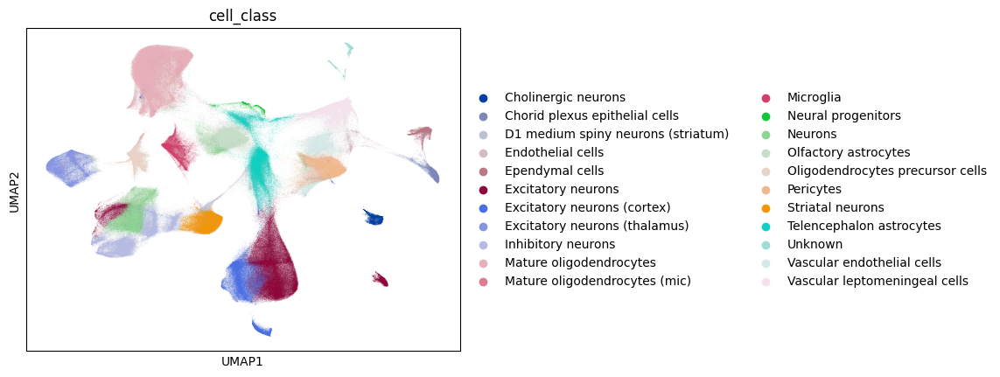

In [3]:
sc.pl.umap(adata, color = 'cell_class')

In [4]:
list(adata.obs.sample_id.unique())

['RB4282',
 'RB4350',
 'RB4401',
 'RB4403',
 'RB4405',
 'RB4498',
 'RB4620',
 'RB4627',
 'RB4630',
 'RB4653',
 'RB4658',
 'RB4676']

In [5]:
%%time
sample_ids = ['RB4282',
 'RB4350',
 'RB4401',
 'RB4403',
 'RB4405',
 'RB4498',
 'RB4620',
 'RB4627',
 'RB4630',
 'RB4653',
 'RB4658',
 'RB4676']
# or: adata.obs["sample_id"].unique().tolist()
ad_sn_list = [
    spatial_neighbourhoods_fast(
        adata[adata.obs["sample_id"] == sid],
        cluster_label="cell_class",
        max_distance=100,
        x_col="x_centroid",
        y_col="y_centroid",
    )
    for sid in sample_ids
]

CPU times: user 18.6 s, sys: 370 ms, total: 19 s
Wall time: 3.23 s


In [6]:
ad_sn_list

[AnnData object with n_obs × n_vars = 81721 × 22
     obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'n_genes_by_counts', 'n_counts', 'n_genes', 'leiden_0.5', 'leiden_1', 'leiden_2', 'cell_class', 'sample_id', 'age', 'sex', 'genotype', 'condition', 'cell_type'
     uns: 'spatial_neighbourhoods'
     obsp: 'neighbors_within_radius',
 AnnData object with n_obs × n_vars = 72889 × 22
     obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'n_genes_by_counts', 'n_counts', 'n_genes', 'leiden_0.5', 'leiden_1', 'leiden_2', 'cell_class

In [7]:
%%time
ad_sn = sc.concat(ad_sn_list, join = 'outer', fill_value = 0)

CPU times: user 80.7 ms, sys: 19.9 ms, total: 101 ms
Wall time: 99.9 ms


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [8]:
%%time
spatial = np.array(ad_sn.obs[['x_centroid','y_centroid']])
ad_sn.obsm['spatial'] = spatial

CPU times: user 1.74 ms, sys: 1.96 ms, total: 3.7 ms
Wall time: 3.24 ms


In [14]:
ad_sn.X = ad_sn.X.astype('float32')

In [15]:
%%time
sc.pp.pca(ad_sn, n_comps=20, svd_solver="randomized")

CPU times: user 9.17 s, sys: 13.7 s, total: 22.8 s
Wall time: 1.67 s


In [18]:
%%time
sc.pp.neighbors(ad_sn, n_neighbors=10, use_rep="X_pca", n_pcs=20)

CPU times: user 4min 31s, sys: 3.58 s, total: 4min 34s
Wall time: 37.4 s


In [23]:
sc.tl.umap(
    ad_sn,
    init_pos="random",
    min_dist=0.2,
    negative_sample_rate=2,    # default 5; lower = faster
    maxiter=200                # additional cap on optimization steps
)

In [ ]:
%%time
for i in [0.01,  0.04, 0.06,0.1,0.15,0.2,0.3,0.5]: 
    key = 'local_neighborhood_'+str(i)
    if key in ad_sn.obs.columns: 
        sc.pl.umap(ad_sn,color=[key],  s = 10)#,save='UMAP_10X_colors.svg')
    else: 
        sc.tl.leiden(ad_sn,resolution=i, key_added = key)
        sc.pl.umap(ad_sn,color=[key],  s = 10)#,save='UMAP_10X_colors.svg')

/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


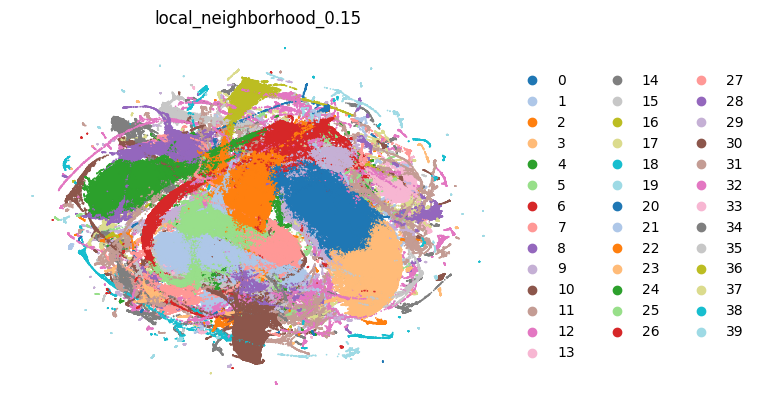

In [15]:
import seaborn as sns

key = "local_neighborhood_0.15"
cats = ad_sn.obs[key].astype("category").cat.categories
palette = sns.color_palette("tab20", n_colors=len(cats)).as_hex()

ad_sn.uns[f"{key}_colors"] = palette
sc.pl.umap(ad_sn, color=key, frameon=False, size=6)

RB4658


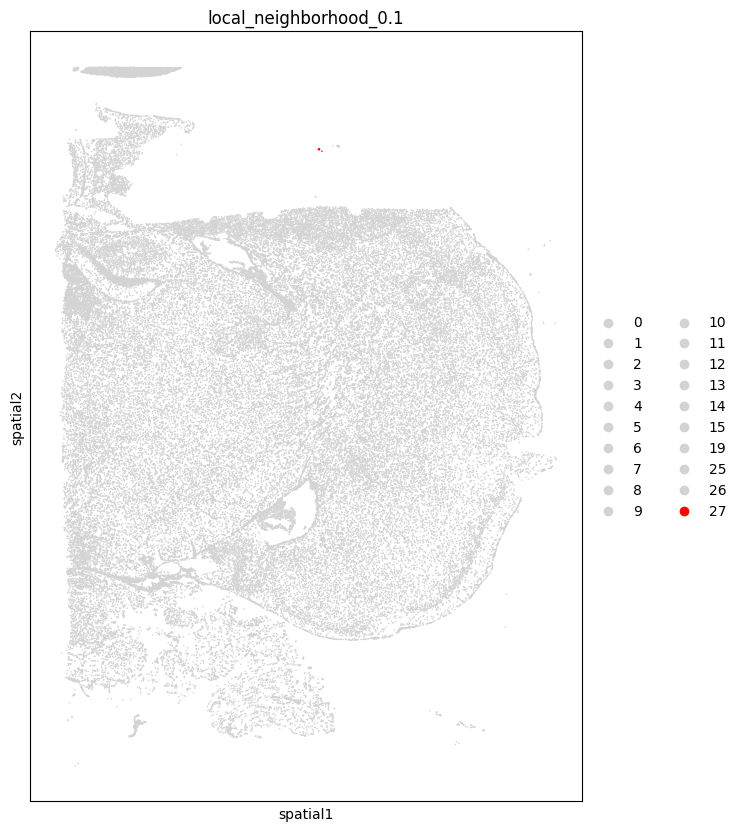

In [69]:
import matplotlib.pyplot as plt
import scanpy as sc

target_cluster = "27"   # <-- put your cluster name here
samples_ = ad_sn[ad_sn.obs['local_neighborhood_0.1'] == target_cluster].obs.sample_id.value_counts().head(5)

for run in list(samples_.index):
    print(run)
    ad_int = ad_sn[ad_sn.obs['sample_id'] == run].copy()
    # build a palette: target cluster → red, others → grey
    clusters = ad_int.obs['local_neighborhood_0.1'].unique().tolist()
    palette = {
        c: ("red" if c == target_cluster else "lightgrey")
        for c in clusters
    }

    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(
            ad_int,
            color="local_neighborhood_0.1",
            spot_size=15,
            palette=palette
        )
    plt.show()

In [25]:
import matplotlib.pyplot as plt

RB4282


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


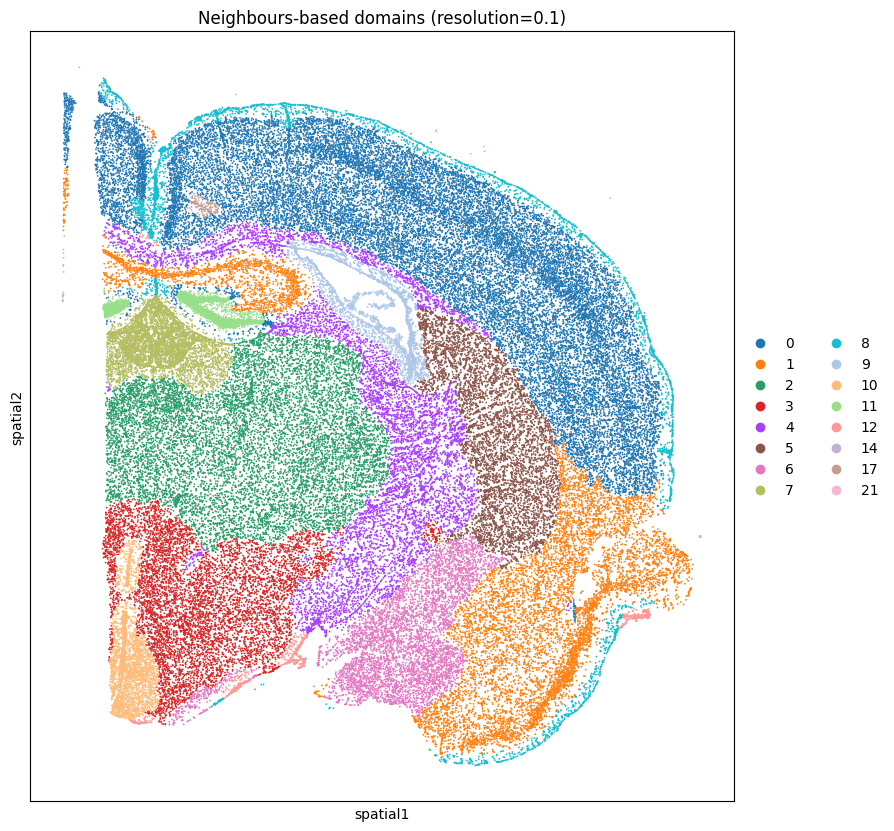

RB4350


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


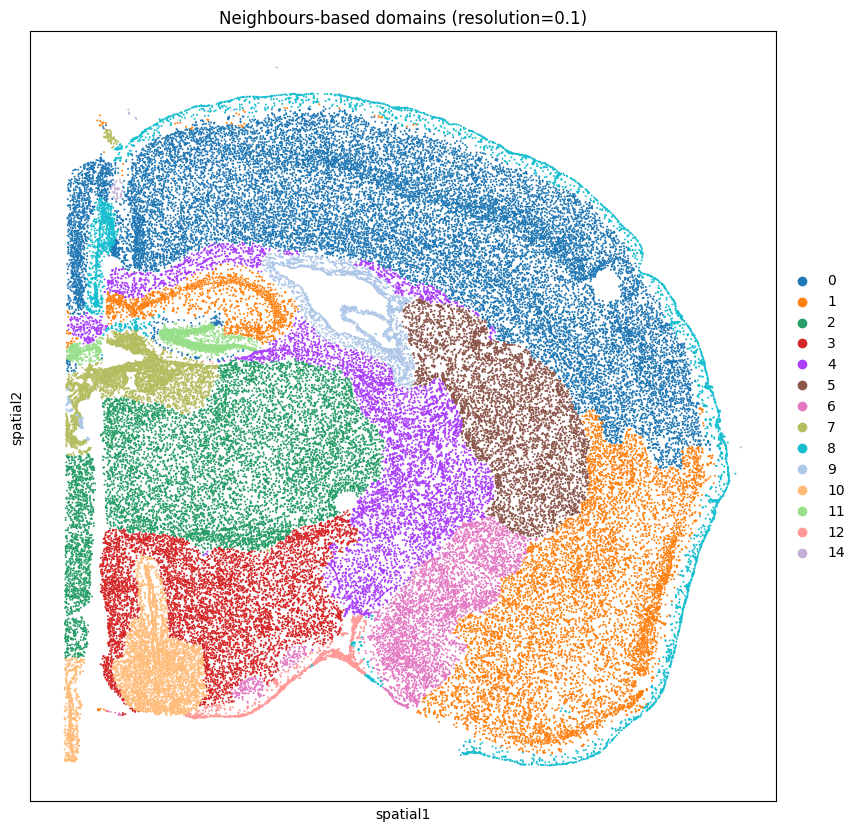

RB4401


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


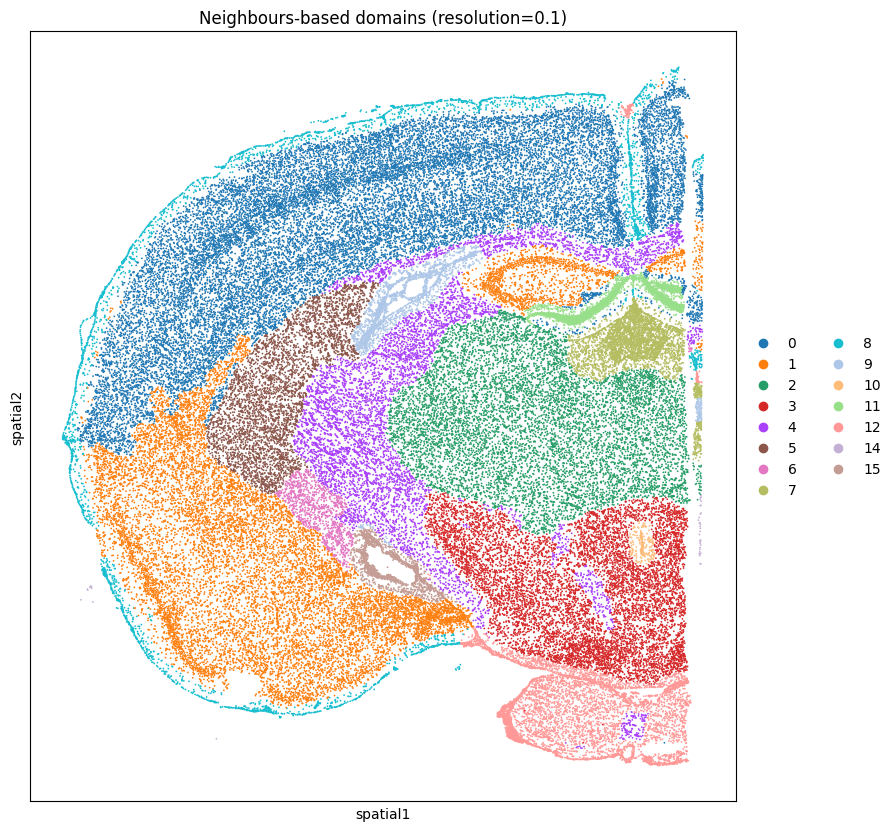

RB4403


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


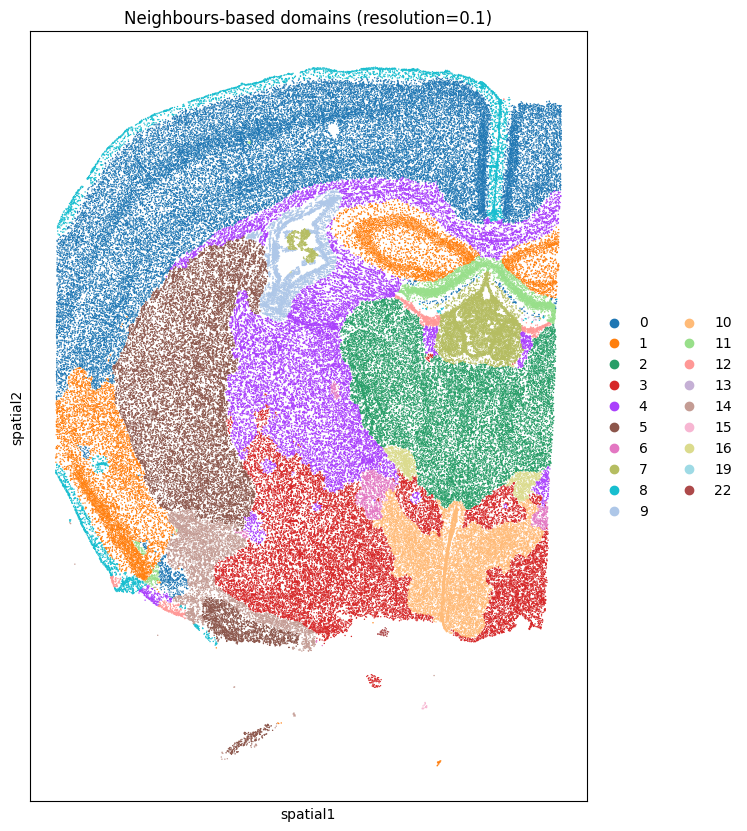

RB4405


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


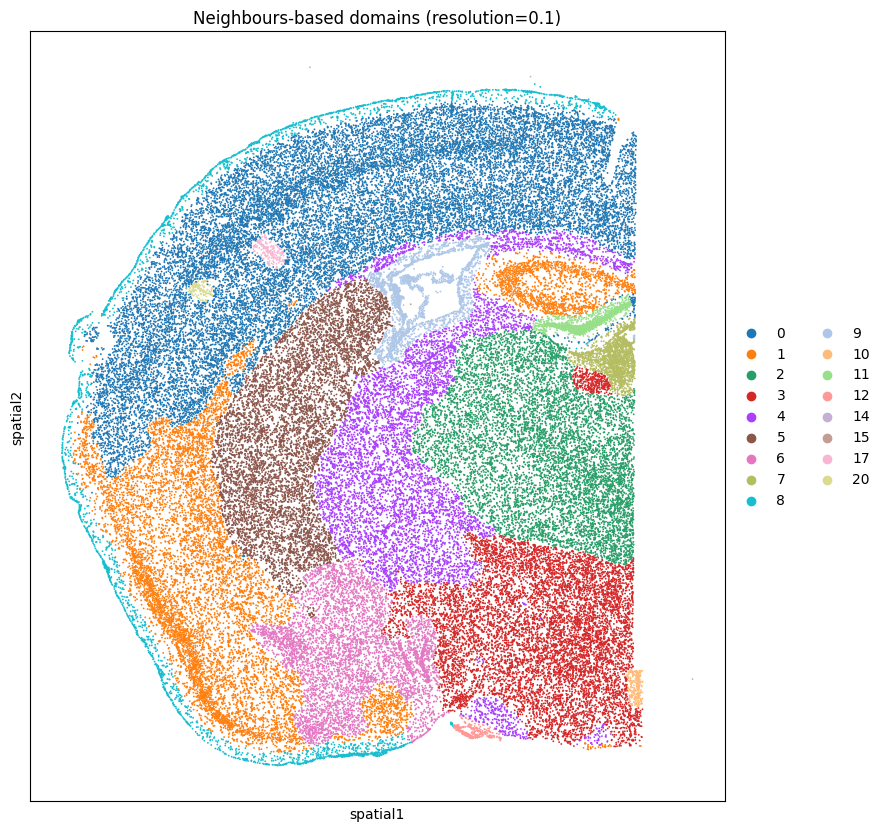

RB4498


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


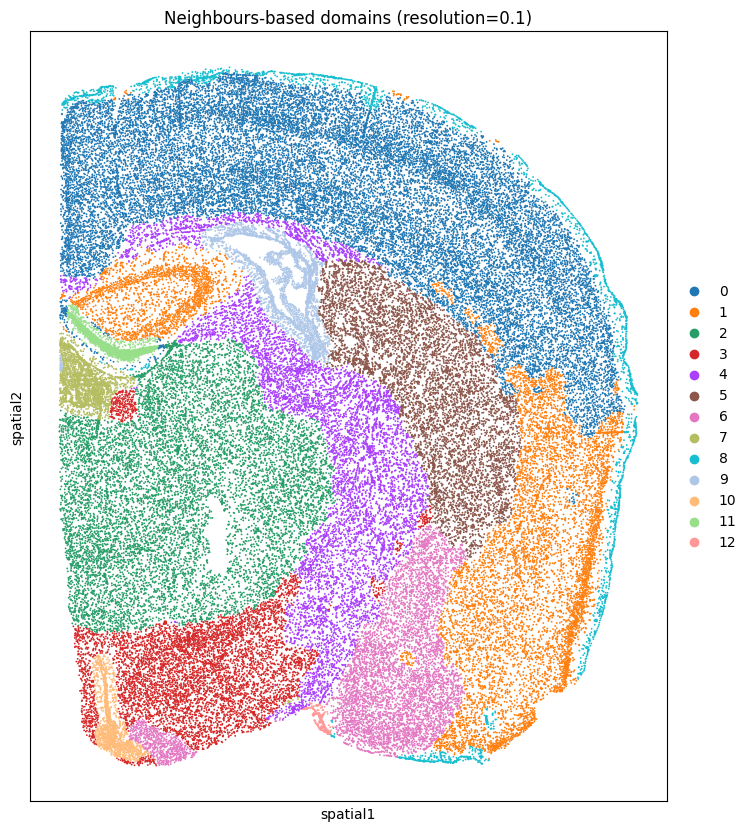

RB4620


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


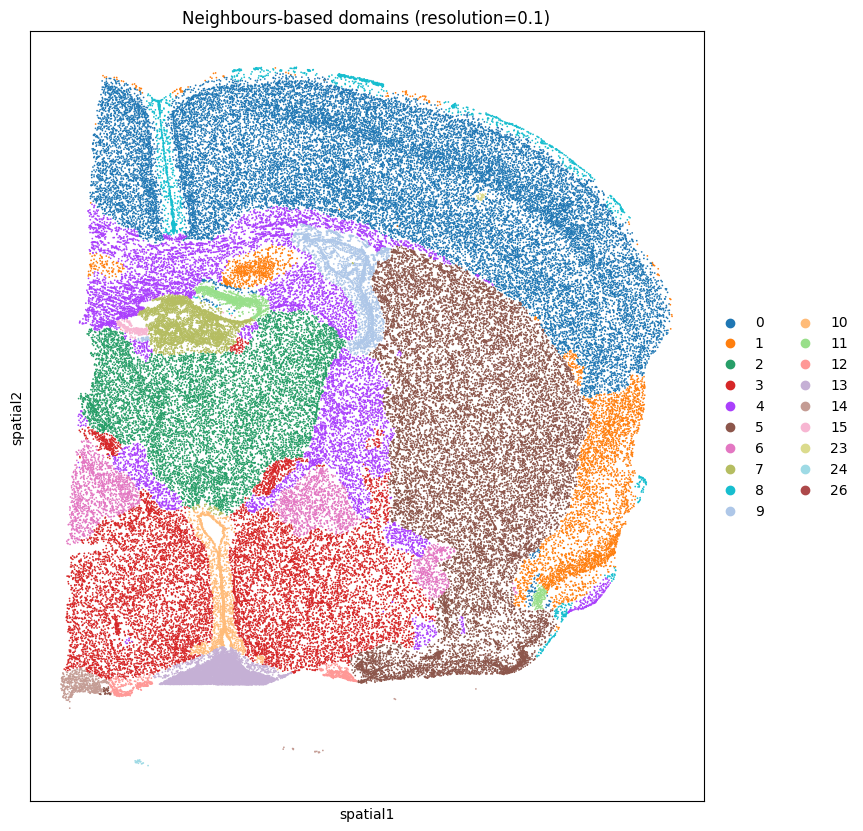

RB4627


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


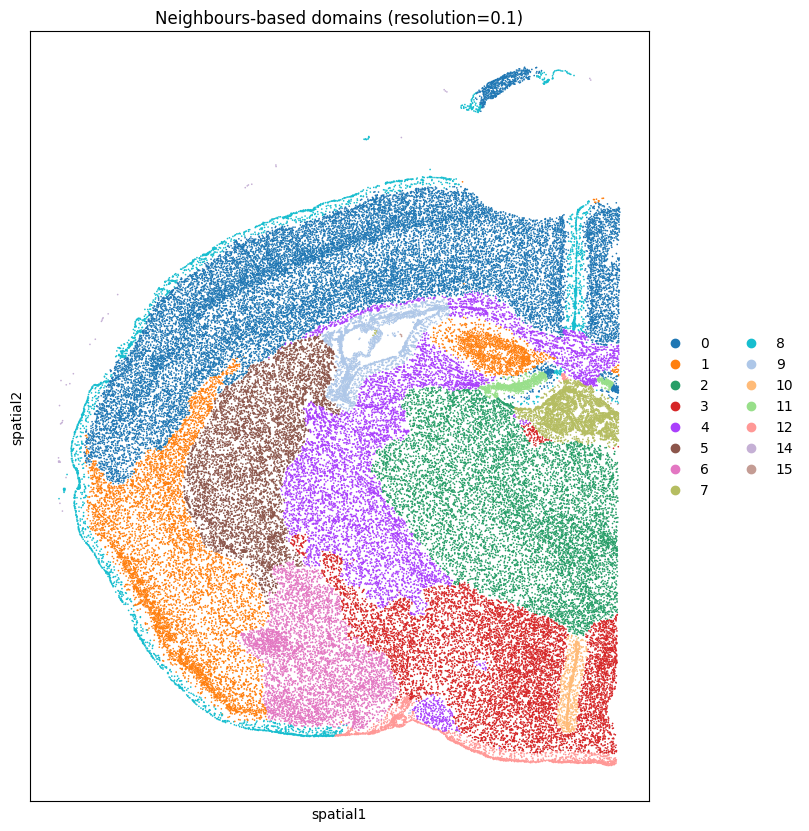

RB4630


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


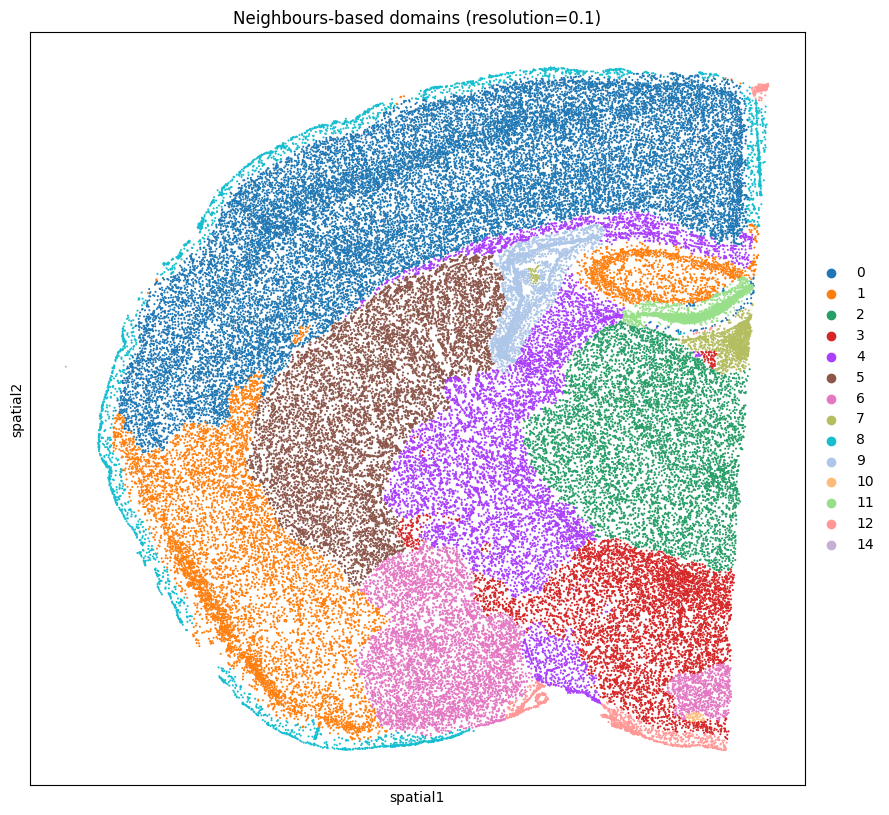

RB4653


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


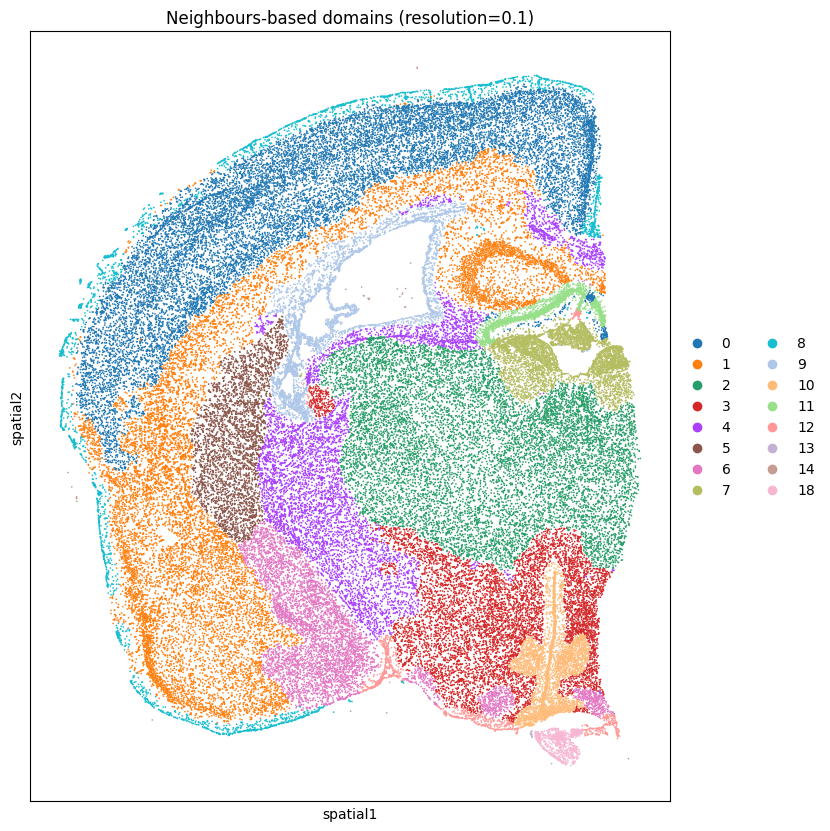

RB4658


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


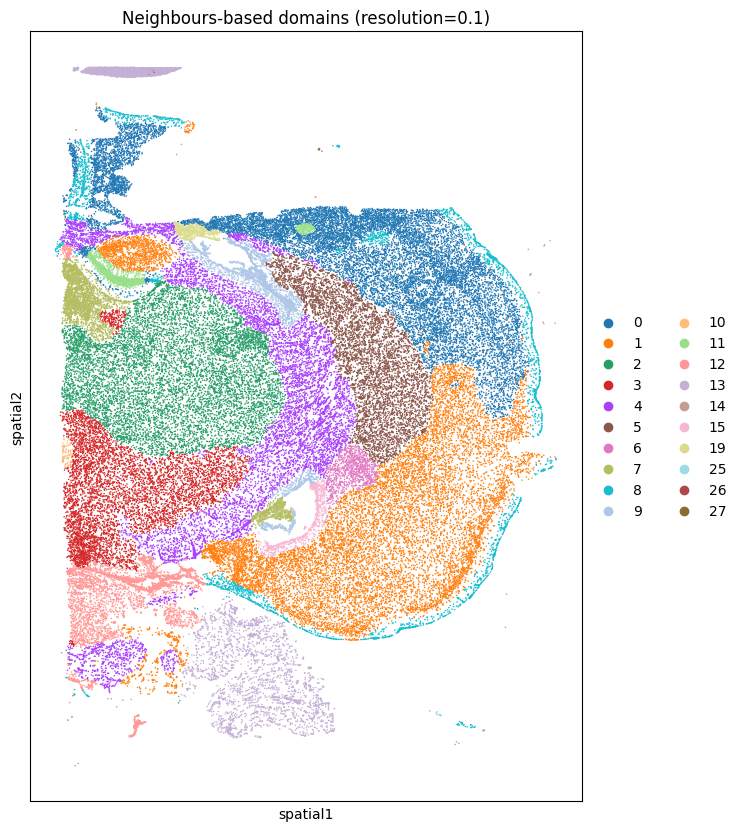

RB4676


/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


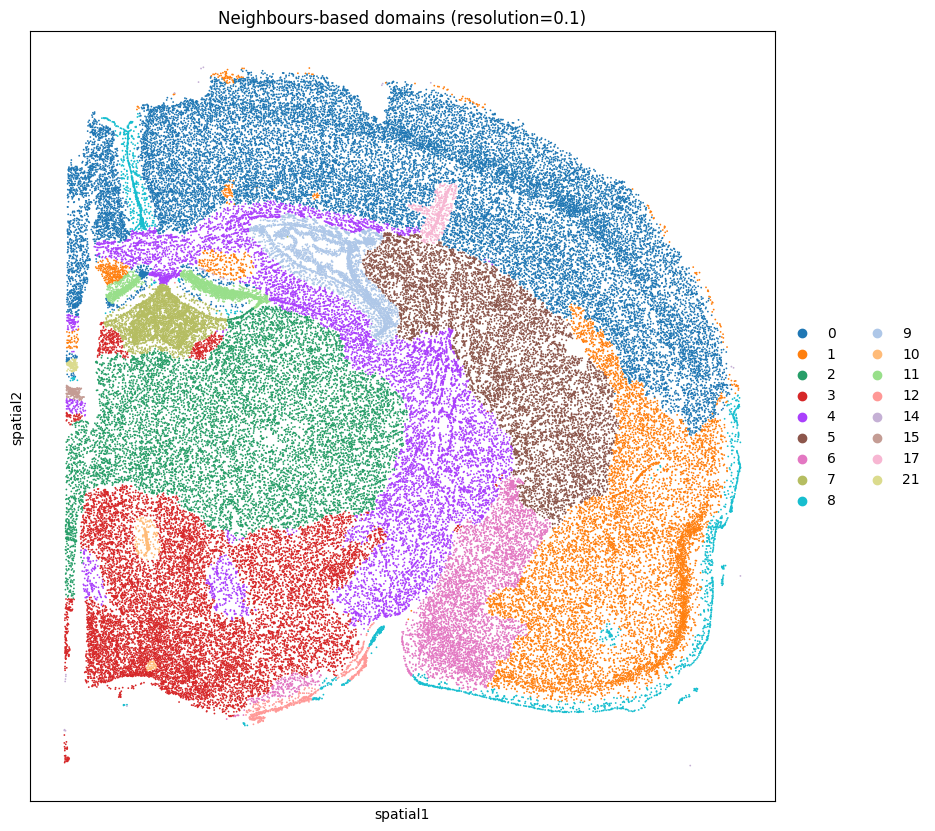

In [18]:
# 5) Plot a spatial map for your favorite resolution:
for sample_id in ad_sn.obs.sample_id.unique():
    print(sample_id)
    with plt.rc_context({"figure.figsize": (10, 10)}):
        ad_sn_ = ad_sn[ad_sn.obs['sample_id'] == sample_id]
        sc.pl.spatial(
            ad_sn_,
            color='local_neighborhood_0.1',
            spot_size=15,
            title="Neighbours-based domains (resolution=0.1)"
        )

In [45]:
import scanpy as sc
import pandas as pd
import scipy
import matplotlib.pyplot as plt

def post_merge(df, labels, post_merge_cutoff, linkage_method='single', 
               linkage_metric='correlation', fcluster_criterion='distance', name='', save=False):
    Z = scipy.cluster.hierarchy.linkage(df.T, method=linkage_method, metric=linkage_metric)
    merged_labels_short = scipy.cluster.hierarchy.fcluster(Z, post_merge_cutoff, criterion=fcluster_criterion)

    # map cluster name to merged label
    label_conversion = dict(zip(df.columns, merged_labels_short))
    new_labels = [label_conversion[i] for i in labels]

    # Plot
    fig, ax = plt.subplots(figsize=(20, 10))
    scipy.cluster.hierarchy.dendrogram(Z, labels=df.columns, color_threshold=post_merge_cutoff, ax=ax)
    ax.hlines(post_merge_cutoff, 0, ax.get_xlim()[1])
    ax.set_title('Merged clusters')
    ax.set_ylabel(linkage_metric, fontsize=20)
    ax.set_xlabel('Pre-merge cluster labels', fontsize=20)
    ax.tick_params(axis="x", labelrotation=90, labelsize=10)  # <-- rotate tick labels
    plt.show()
    if save:
        fig.savefig(f"{name}.svg", dpi=500)
    
    return new_labels

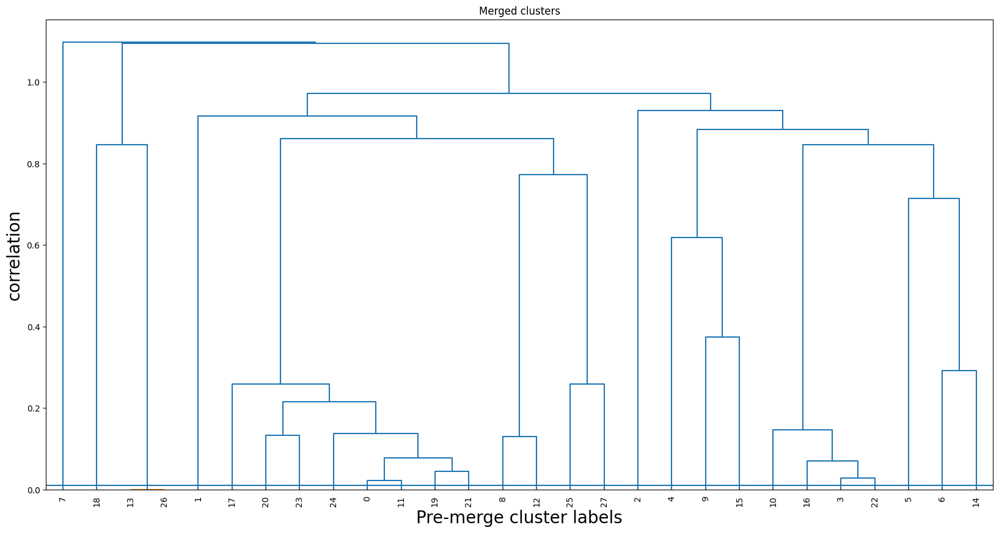

In [47]:
# Compute cluster-level mean expression
cluster_key = 'local_neighborhood_0.1'
expr = pd.DataFrame(ad_sn.X, index=ad_sn.obs_names, columns=ad_sn.var_names)
cluster_means = expr.groupby(ad_sn.obs[cluster_key]).mean().T  # genes x clusters

# Run post-merge
merged_labels = post_merge(cluster_means, labels=ad_sn.obs[cluster_key].tolist(),
                           post_merge_cutoff=0.01,
                           linkage_metric='correlation',
                           linkage_method='average',
                           name='SupFig3Dend',
                           save=False)

# Add new merged label to AnnData object
ad_sn.obs['merged_cluster'] = merged_labels
ad_sn.obs['merged_cluster'] = ad_sn.obs['merged_cluster'].astype(str)

In [48]:
import warnings
warnings.filterwarnings("ignore")

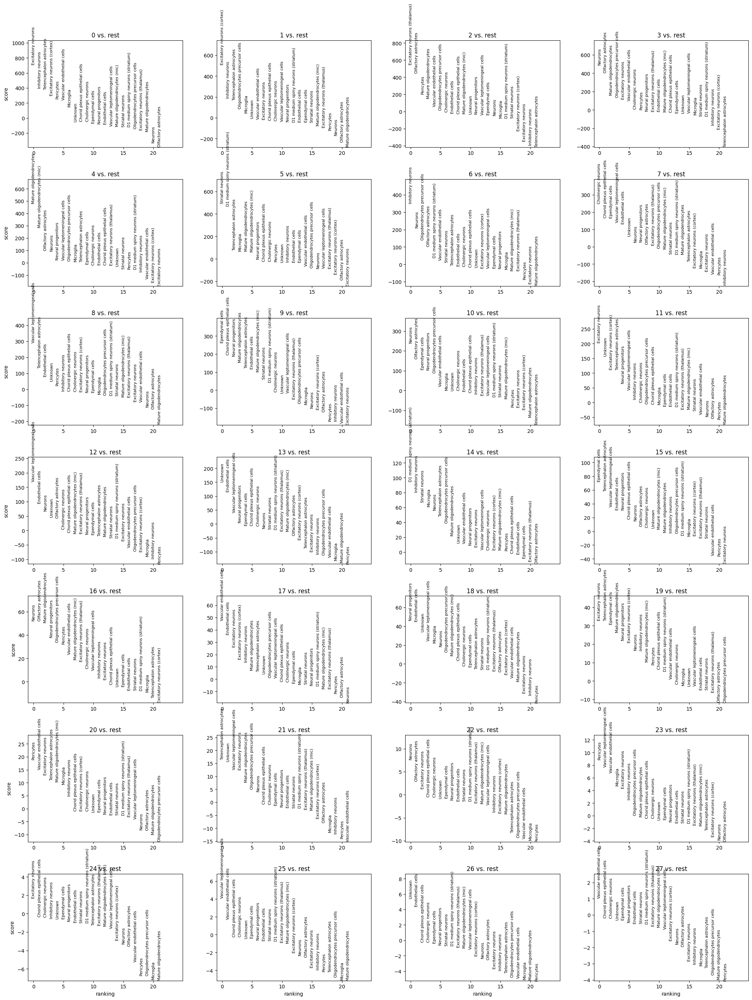

0
Excitatory neurons Inhibitory neurons Telencephalon astrocytes Excitatory neurons (cortex) Pericytes Vascular endothelial cells Microglia Unknown Chorid plexus epithelial cells Cholinergic neurons
 
1
Excitatory neurons (cortex) Inhibitory neurons Telencephalon astrocytes Oligodendrocytes precursor cells Microglia Unknown Vascular endothelial cells Excitatory neurons Chorid plexus epithelial cells Cholinergic neurons
 
2
Excitatory neurons (thalamus) Olfactory astrocytes Pericytes Mature oligodendrocytes Vascular endothelial cells Oligodendrocytes precursor cells Cholinergic neurons Endothelial cells Chorid plexus epithelial cells Mature oligodendrocytes (mic)
 
3
Neurons Olfactory astrocytes Mature oligodendrocytes Oligodendrocytes precursor cells Excitatory neurons Vascular endothelial cells Cholinergic neurons Pericytes Neural progenitors Excitatory neurons (thalamus)
 
4
Mature oligodendrocytes Mature oligodendrocytes (mic) Olfactory astrocytes Neurons Neural progenitors Vascular

In [49]:
sc.tl.rank_genes_groups(ad_sn, groupby='local_neighborhood_0.1', method='wilcoxon')
# See top 5 marker genes per cluster
sc.pl.rank_genes_groups(ad_sn, n_genes=25, sharey=False)

marker_genes = pd.DataFrame({
    group: ad_sn.uns['rank_genes_groups']['names'][group][:10]
    for group in ad_sn.uns['rank_genes_groups']['names'].dtype.names
})
marker_genes.head()
#marker_genes.to_csv('../data/broad_markers_leiden0-5.csv')
for col in marker_genes.columns: 
    print(col)
    genes = marker_genes[col].tolist()
    print(" ".join(genes))
    print(' ')

In [50]:
dict(zip(ad_sn.obs["local_neighborhood_0.1"].cat.categories, ad_sn.obs["local_neighborhood_0.1"].cat.categories))

{'0': '0',
 '1': '1',
 '2': '2',
 '3': '3',
 '4': '4',
 '5': '5',
 '6': '6',
 '7': '7',
 '8': '8',
 '9': '9',
 '10': '10',
 '11': '11',
 '12': '12',
 '13': '13',
 '14': '14',
 '15': '15',
 '16': '16',
 '17': '17',
 '18': '18',
 '19': '19',
 '20': '20',
 '21': '21',
 '22': '22',
 '23': '23',
 '24': '24',
 '25': '25',
 '26': '26',
 '27': '27'}

In [70]:
anno = {'0': 'Isocortex',
 '1': 'Olfactory areas',
 '2': 'Thalamus',
 '3': 'Hypothalamus',
 '4': 'Palladium + corpus callosum',
 '5': 'Striatum',
 '6': 'Striatum like amygdalar nuclei',
 '7': 'Medial habenula',
 '8': 'Meninges',
 '9': 'Lateral ventricle I',
 '10': 'Third ventricle',
 '11': 'Dentate gyrus',
 '12': 'Hindbrain', # not too sure about this one
 '13': 'Uknown',
 '14': 'Cortical subplate',
 '15': 'Lateral venricle II',
 '16': 'Perireunensis nucleus',
 '17': 'Isocortex',
 '18': 'Meninges',
 '19': 'Unknown',
 '20': 'Isocortex',
 '21': 'Unknown',
 '22': 'Unknown',
 '23': 'Unknown',
 '24': 'Unknown',
 '25': 'Isocortex',
 '26': 'Unknown',
 '27': 'Unknown'}

In [71]:
ad_sn.obs['compartment'] = ad_sn.obs["local_neighborhood_0.1"].map(anno)

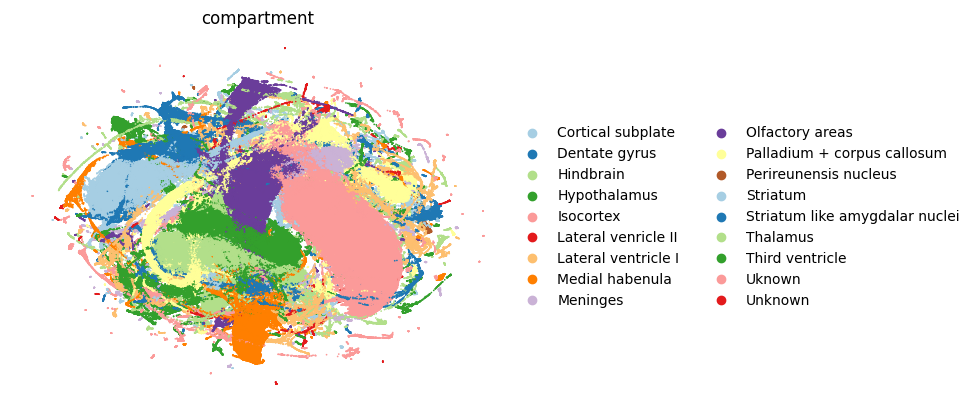

In [79]:
import seaborn as sns

key = "compartment"
cats = ad_sn.obs[key].astype("category").cat.categories
palette = sns.color_palette("Paired", n_colors=len(cats)).as_hex()

ad_sn.uns[f"{key}_colors"] = palette
sc.pl.umap(ad_sn, color=key, frameon=False, size=6)

RB4282


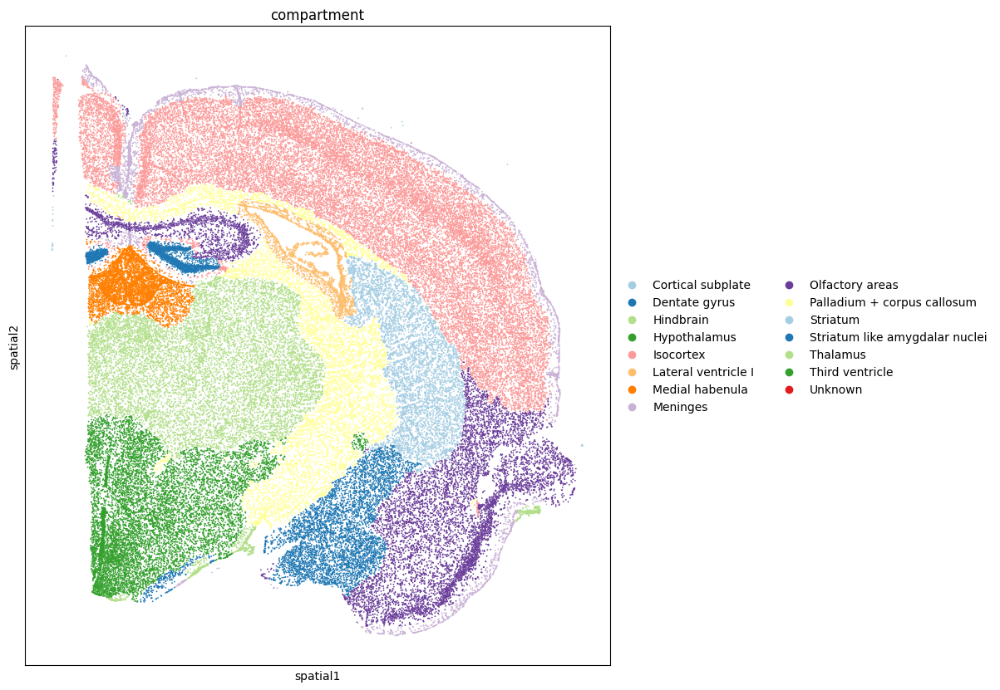

RB4350


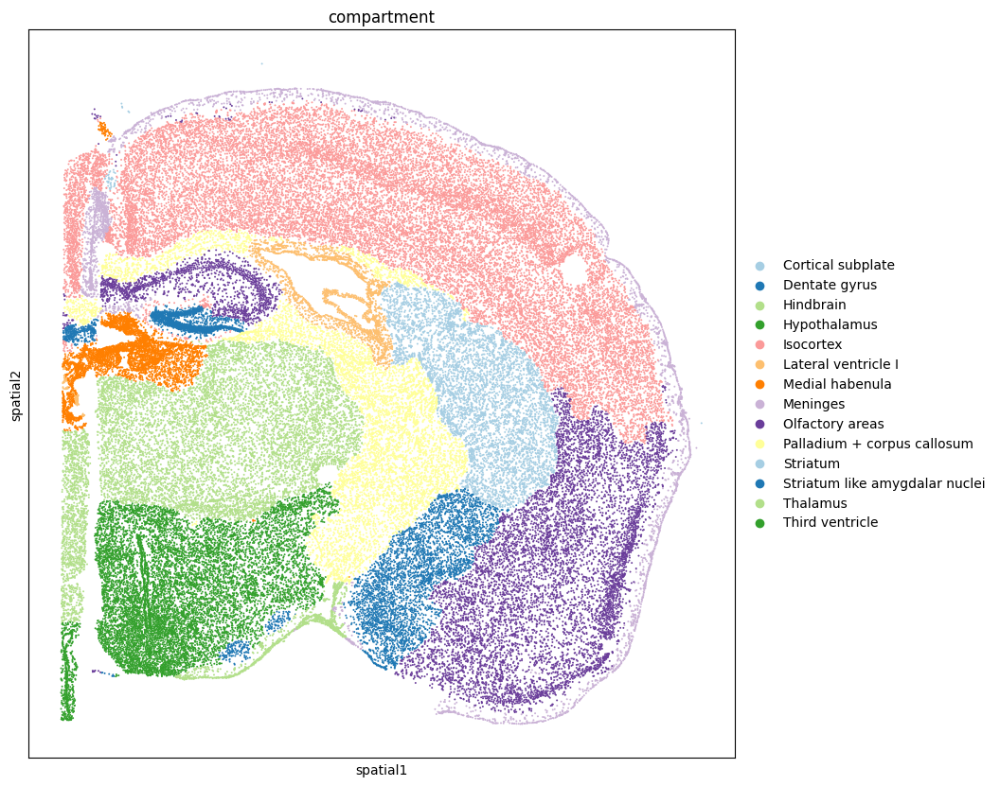

RB4401


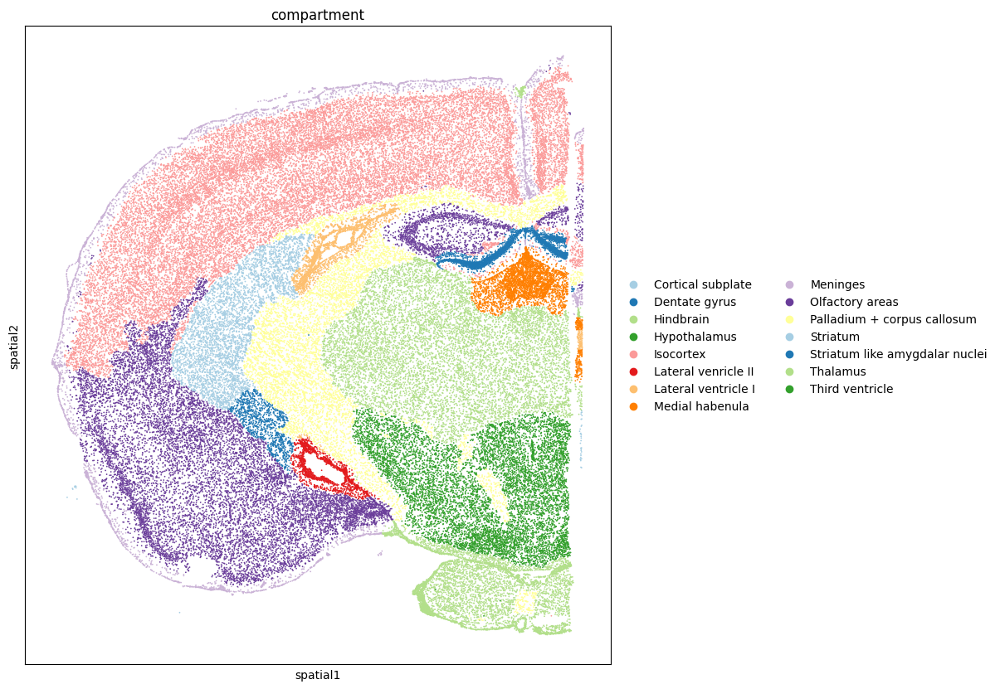

RB4403


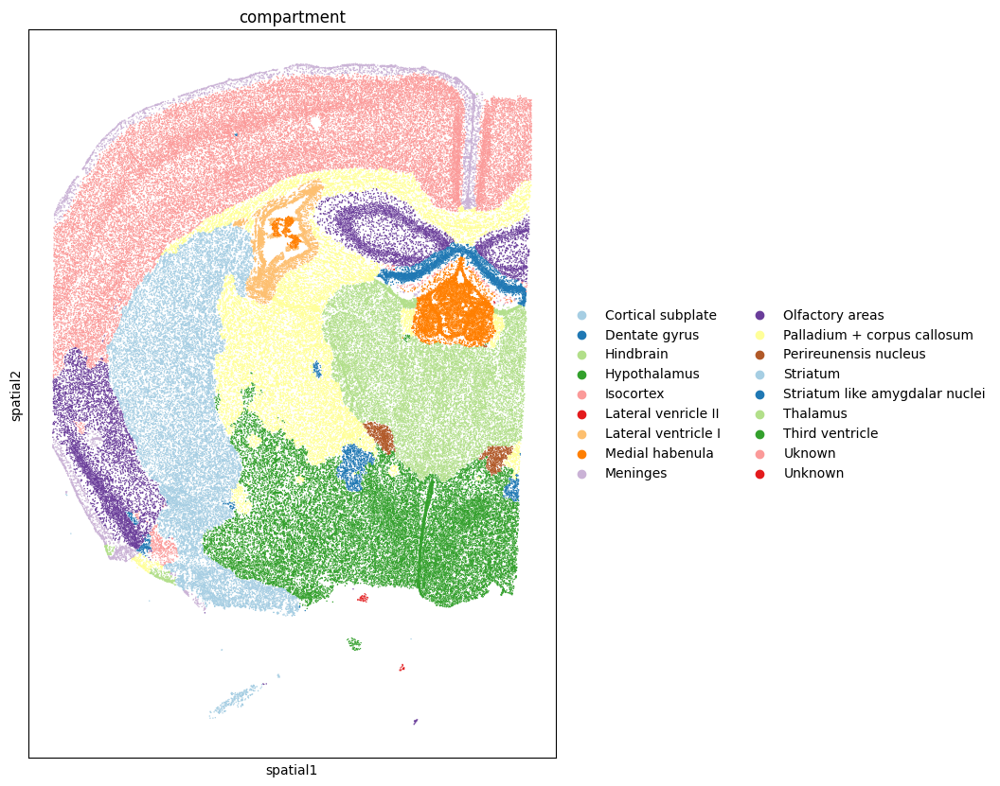

RB4405


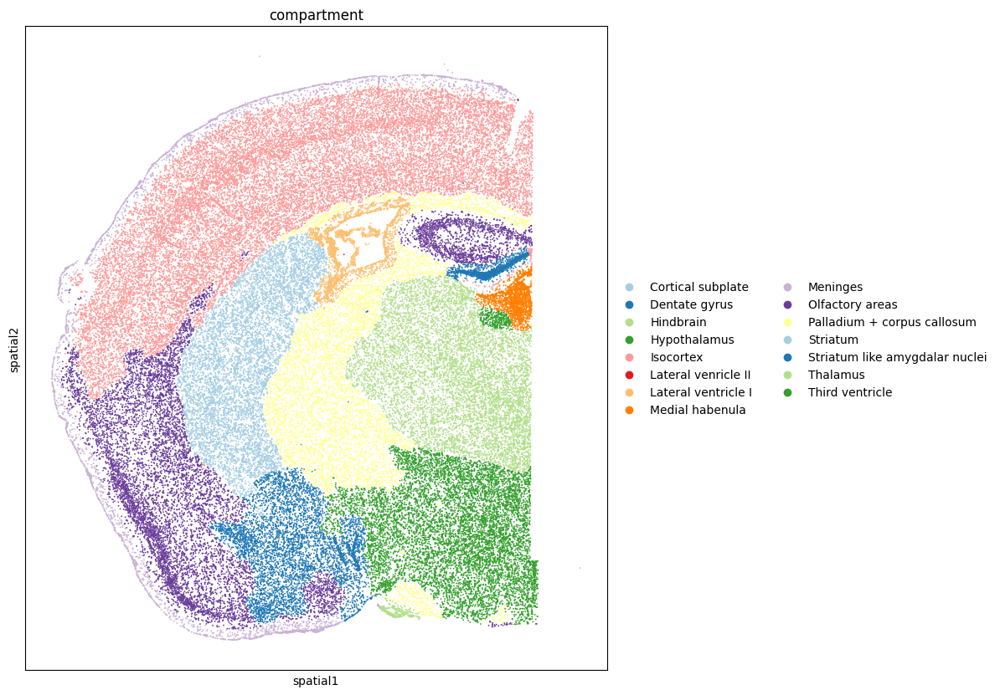

RB4498


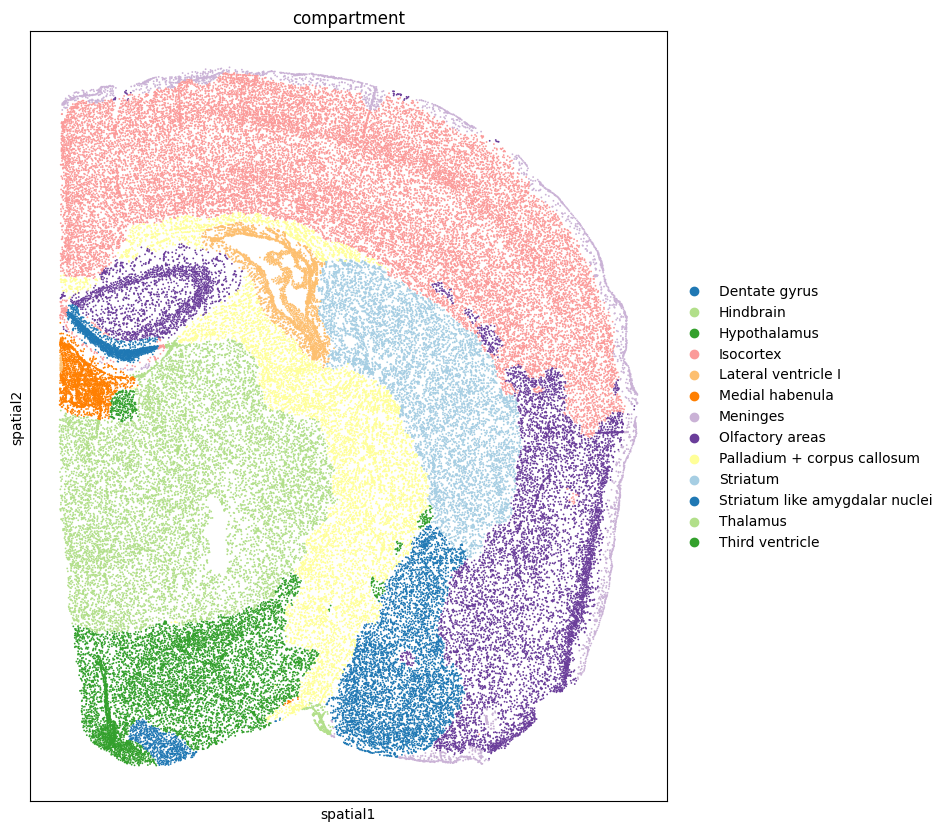

RB4620


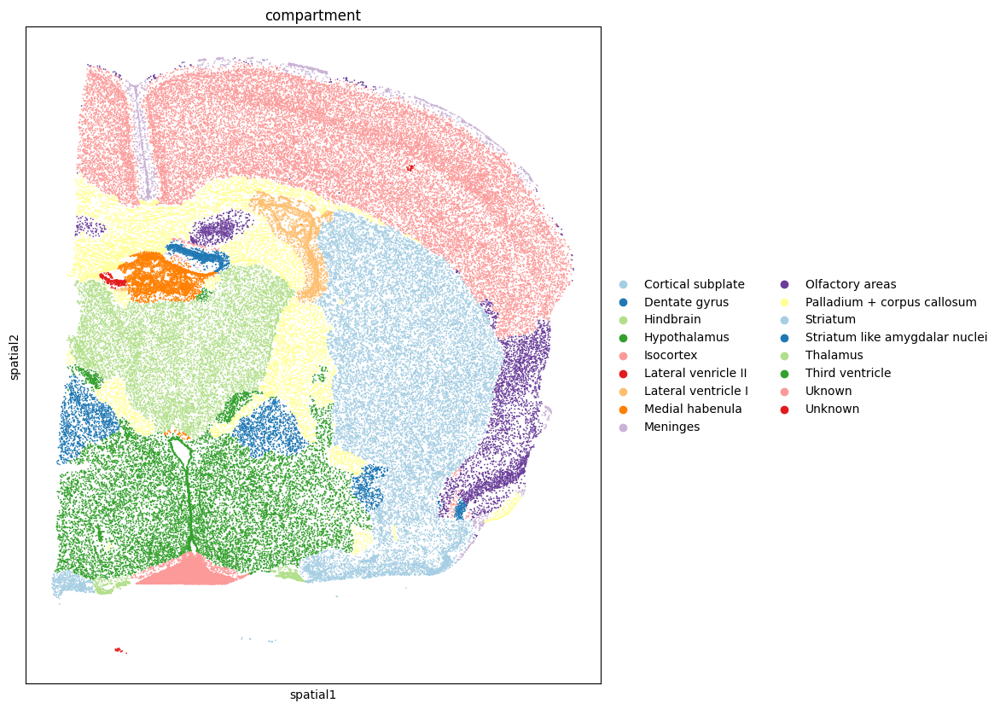

RB4627


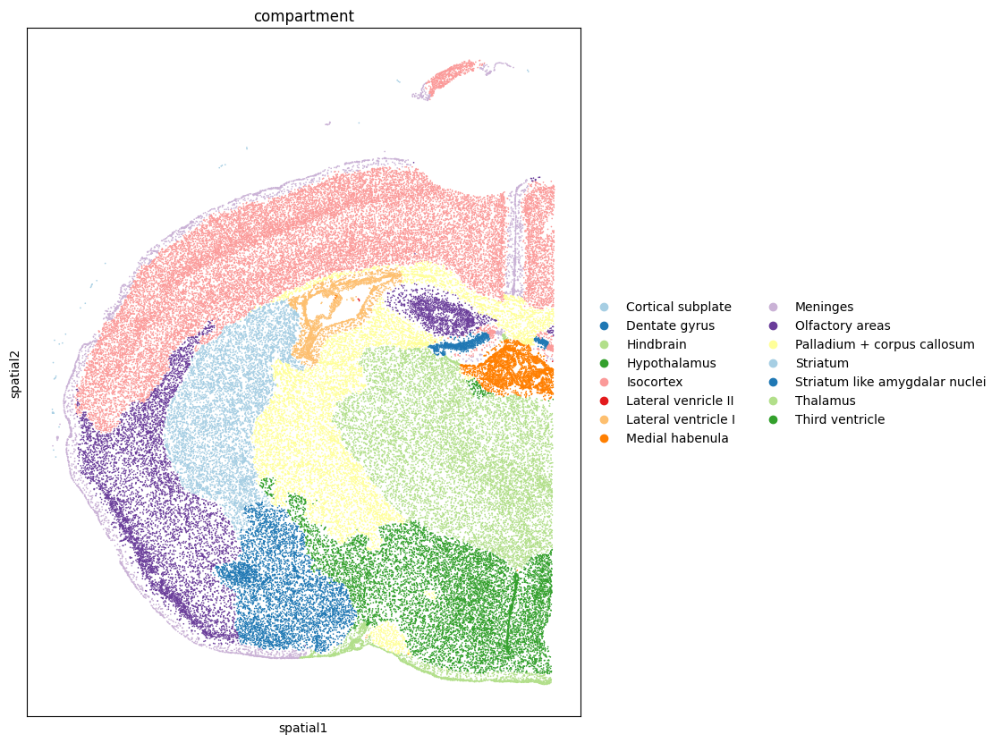

RB4630


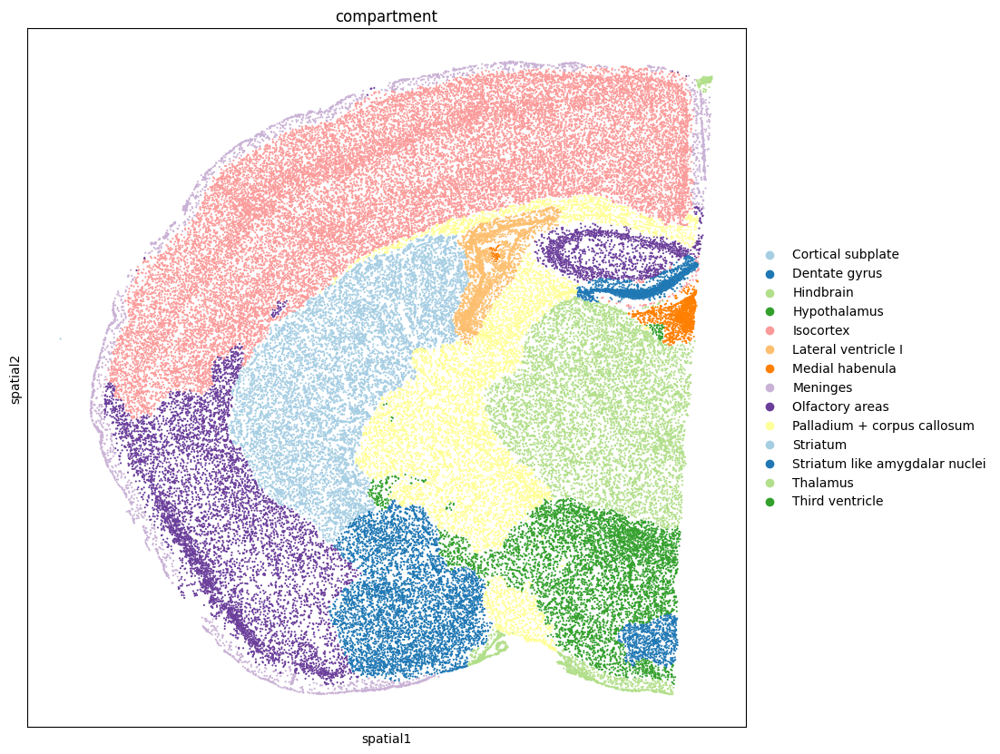

RB4653


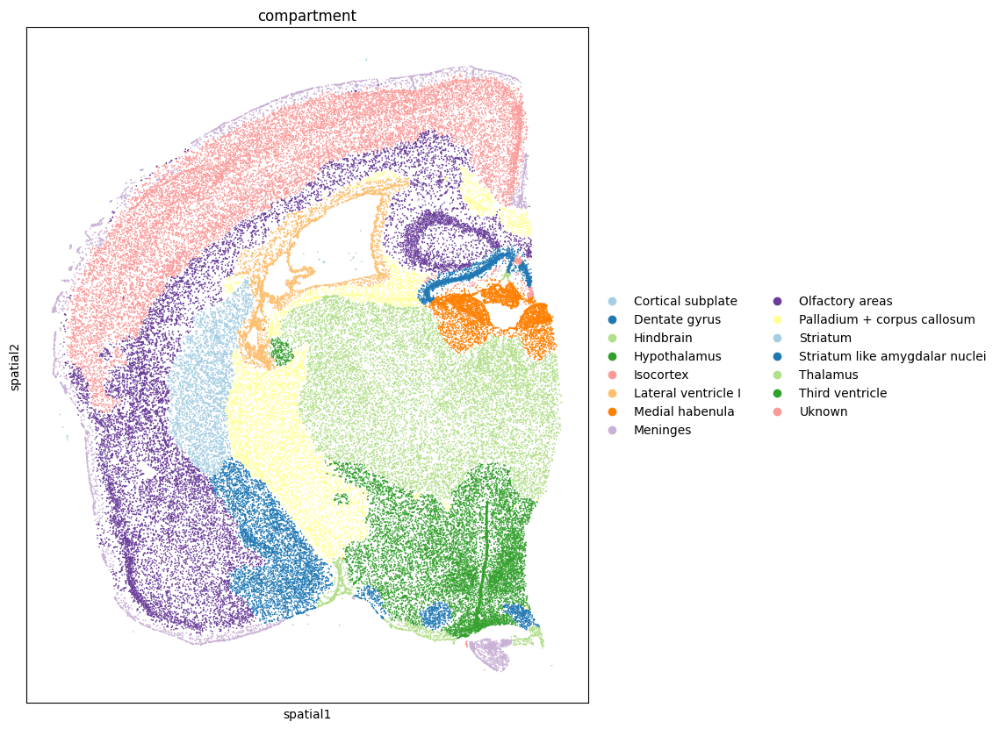

RB4658


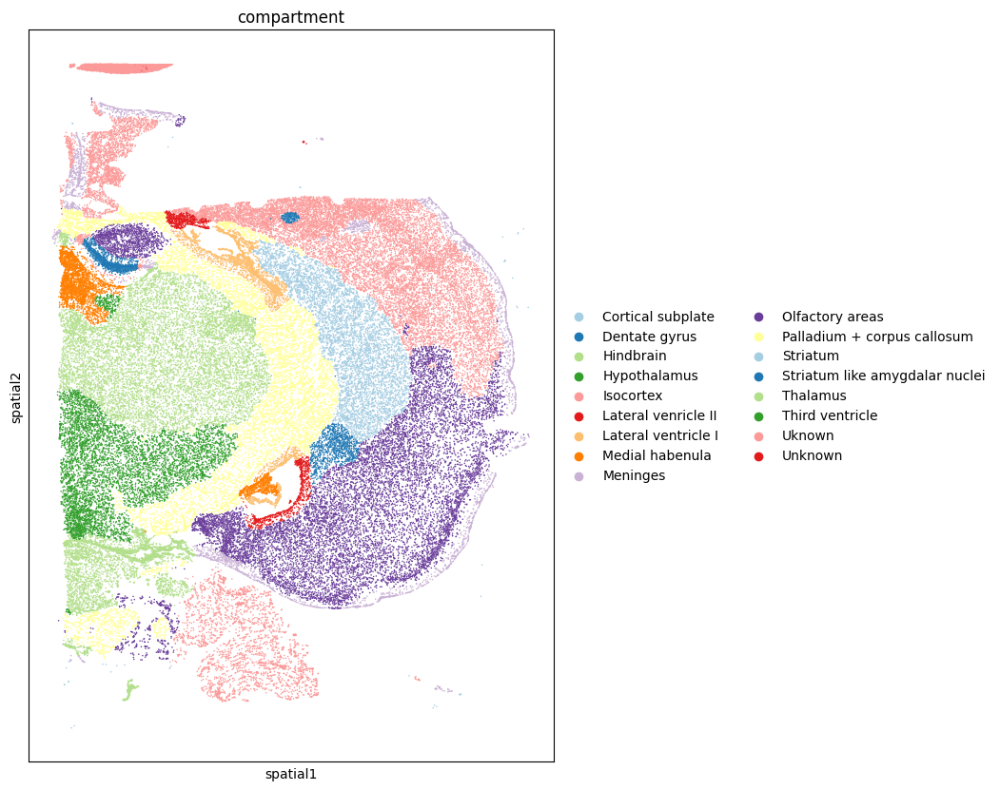

RB4676


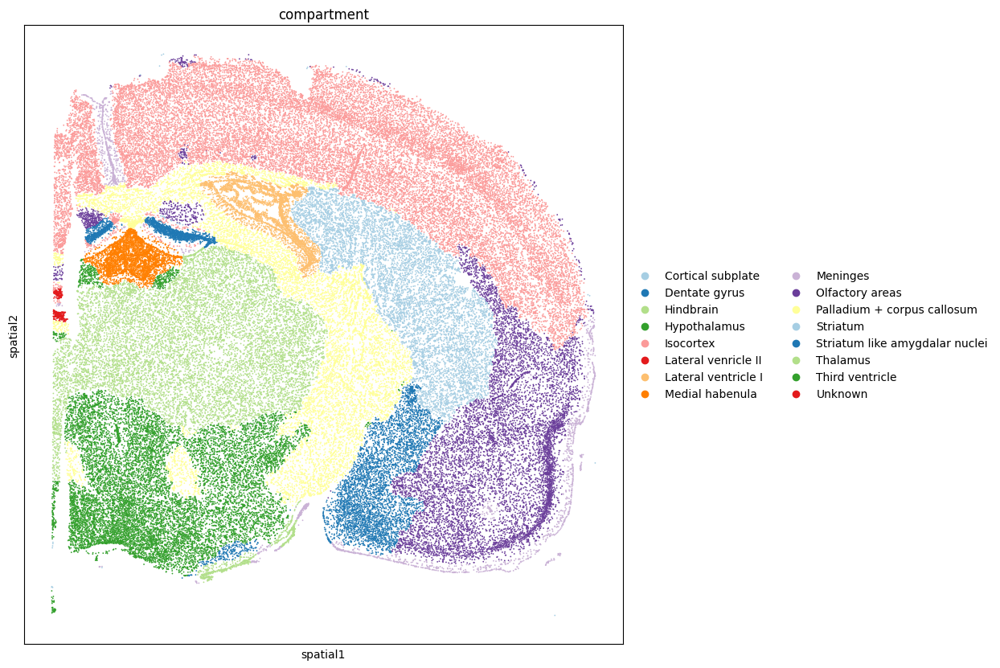

In [80]:
for run in ad_sn.obs['sample_id'].unique():
    print(run)
    ad_int = ad_sn[ad_sn.obs['sample_id'] == run]

    with plt.rc_context({'figure.figsize': (20, 10)}):
        sc.pl.spatial(ad_int, spot_size=15, color = 'compartment')
    plt.show()
    

In [81]:
adata.obs['compartment'] = adata.obs.index.map(dict(zip(ad_sn.obs.index,ad_sn.obs.compartment)))

In [83]:
adata.obs['compartment']

cell_id
aaaaakjg-1          Isocortex
aaaaikjn-1    Olfactory areas
aaaapoln-1    Olfactory areas
aaacmkgf-1          Isocortex
aaaefdnf-1          Isocortex
                   ...       
oifndkbo-1       Hypothalamus
oifolalk-1       Hypothalamus
oifphdni-1       Hypothalamus
oigabhlk-1       Hypothalamus
oigafpoe-1       Hypothalamus
Name: compartment, Length: 980474, dtype: object

In [86]:
adata.write('../data/mtDNA_DSB_5k_clustered_manual_annotation_compartment.h5ad')

In [2]:
adata = sc.read('../data/mtDNA_DSB_5k_clustered_manual_annotation_compartment.h5ad')

/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

def plot_spatial_compact(
    ad,
    color="leiden_2",
    groupby="sample_id",
    spot_size=18,
    cols=3,
    height=8,
    legend_col_width=1.2,
    palette=None,          # <- NEW: dict {category: "#hex"} or list in desired order
):
    # --- categories from the FULL object (freeze order) ---
    cats = ad.obs[color].astype("category").cat.categories

    # --- build a shared color list in that order ---
    if isinstance(palette, dict):
        cols_list = [palette[c] for c in cats]
    elif isinstance(palette, (list, tuple)):
        if len(palette) < len(cats):
            raise ValueError("Palette list shorter than number of categories.")
        cols_list = list(palette)[:len(cats)]
    elif f"{color}_colors" in ad.uns:
        # reuse existing palette if present on the full object
        cols_list = list(ad.uns[f"{color}_colors"])
        if len(cols_list) != len(cats):
            raise ValueError(f"{color}_colors length does not match categories.")
    else:
        base = sc.plotting.palettes.default_64
        reps = int(np.ceil(len(cats) / len(base)))
        cols_list = (base * reps)[:len(cats)]

    # store on the full object too (handy if you plot elsewhere later)
    ad.uns[f"{color}_colors"] = cols_list

    # --- layout ---
    sids = list(ad.obs[groupby].unique())
    n = len(sids)
    rows = int(np.ceil(n / cols))

    panel_w = height * cols * 0.6 / rows
    fig_w = panel_w + legend_col_width
    fig = plt.figure(figsize=(fig_w, height), constrained_layout=False)

    gs = GridSpec(
        rows, cols + 1, figure=fig,
        width_ratios=[1]*cols + [legend_col_width / (fig_w - legend_col_width)],
        wspace=0.02, hspace=0.02
    )

    # --- panels ---
    for i, sid in enumerate(sids):
        r, c = divmod(i, cols)
        ax = fig.add_subplot(gs[r, c])

        ad_sub = ad[ad.obs[groupby] == sid].copy()

        # CRUCIAL: force identical categories & palette on each subset
        ad_sub.obs[color] = ad_sub.obs[color].astype("category")
        ad_sub.obs[color] = ad_sub.obs[color].cat.set_categories(cats)
        ad_sub.uns[f"{color}_colors"] = cols_list

        sc.pl.spatial(
            ad_sub, color=color, spot_size=spot_size,
            show=False, ax=ax, legend_loc=None, frameon=False, title=str(sid)
        )
        ax.set_xlabel(""); ax.set_ylabel("")
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # blank unused
    for j in range(n, rows*cols):
        r, c = divmod(j, cols)
        fig.add_subplot(gs[r, c]).axis("off")

    # --- legend ---
    ax_leg = fig.add_subplot(gs[:, -1])
    ax_leg.axis("off")
    handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=cols_list[k], markersize=7, label=str(cat))
        for k, cat in enumerate(cats)
    ]
    ax_leg.legend(handles=handles, title=color, frameon=False, loc="center left")

    fig.subplots_adjust(left=0.01, right=0.98, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)
    plt.show()

In [21]:
adata.obs["compartment"] = (
    adata.obs["compartment"]
    .replace({"Olfactory areas": "Olfactory areas + Hippocampal formation"})
    .astype("category")
)

In [23]:
adata.obs["compartment"]

cell_id
aaaaakjg-1                                  Isocortex
aaaaikjn-1    Olfactory areas + Hippocampal formation
aaaapoln-1    Olfactory areas + Hippocampal formation
aaacmkgf-1                                  Isocortex
aaaefdnf-1                                  Isocortex
                               ...                   
oifndkbo-1                               Hypothalamus
oifolalk-1                               Hypothalamus
oifphdni-1                               Hypothalamus
oigabhlk-1                               Hypothalamus
oigafpoe-1                               Hypothalamus
Name: compartment, Length: 980474, dtype: category
Categories (18, object): ['Cortical subplate', 'Dentate gyrus', 'Hindbrain', 'Hypothalamus', ..., 'Thalamus', 'Third ventricle', 'Uknown', 'Unknown']

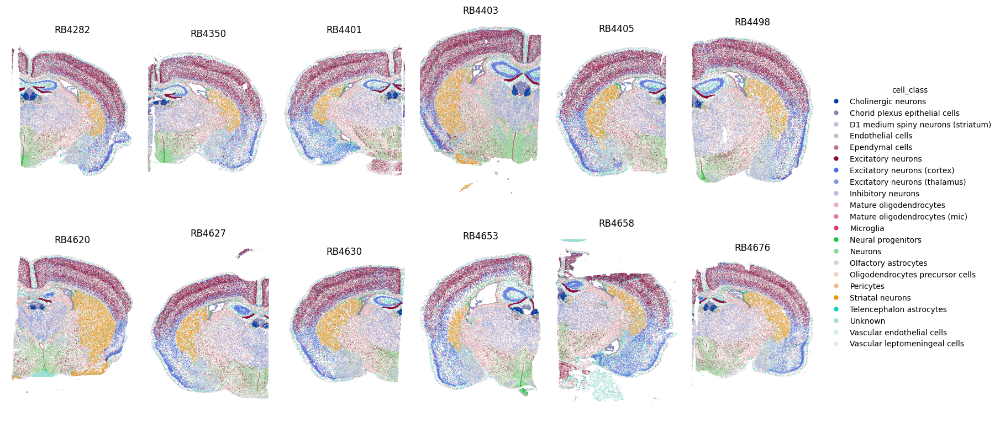

In [27]:

plot_spatial_compact(adata, color="cell_class", groupby="sample_id",spot_size=20,
    cols=6,
    height=8,
    legend_col_width=1.0,)

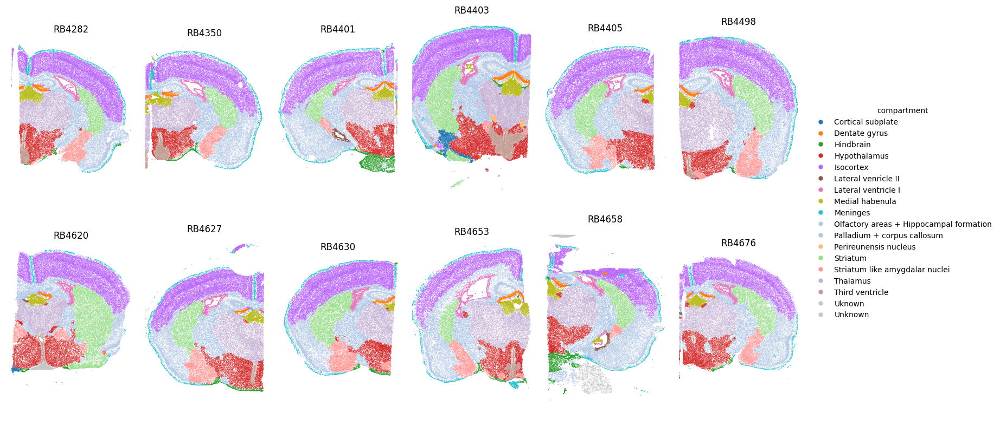

In [25]:
compartment_palette = {
    "Cortical subplate": "#1f77b4",
    "Dentate gyrus": "#ff7f0e",
    "Hindbrain": "#2ca02c",
    "Hypothalamus": "#d62728",
    "Isocortex": "#b963fc",
    "Lateral venricle II": "#8c564b",
    "Lateral ventricle I": "#e377c2",
    "Meninges": "#29c0d2",
    "Medial habenula": "#bcbd22",
    "Olfactory areas + Hippocampal formation": "#b4c9e7",
    "Palladium + corpus callosum": "#aec7e8",
    "Perireunensis nucleus": "#ffbb78",
    "Striatum": "#98df8a",
    "Striatum like amygdalar nuclei": "#ff9896",
    "Thalamus": "#c5b0d5",
    "Third ventricle": "#c49c94",
    "Unknown": "#c7c7c7",
    "Uknown": "#c7c7c7"
}
plot_spatial_compact(adata, color="compartment", groupby="sample_id", palette=compartment_palette,spot_size=20,
    cols=6,
    height=8,
    legend_col_width=1.0,)

In [31]:
adata[adata.obs.compartment == 'Hindbrain'].obs.cell_class.value_counts()

cell_class
Neurons                               41319
Mature oligodendrocytes               18601
Olfactory astrocytes                  14184
Excitatory neurons                     9358
Pericytes                              5255
Vascular endothelial cells             4511
Oligodendrocytes precursor cells       3134
Microglia                              2763
Inhibitory neurons                     2311
Vascular leptomeningeal cells           453
Excitatory neurons (thalamus)           409
Telencephalon astrocytes                324
Endothelial cells                       194
Mature oligodendrocytes (mic)           175
Neural progenitors                       76
Cholinergic neurons                      57
Ependymal cells                          25
Unknown                                  16
Striatal neurons                         14
Excitatory neurons (cortex)               9
D1 medium spiny neurons (striatum)        6
Name: count, dtype: int64

In [93]:
del ad_sn.uns['compartment_colors']

In [94]:
ad_sn.write('../data/mtDNA_DSB_5k_neigh.h5ad')

In [13]:
ad_sn = sc.read('../data/mtDNA_DSB_5k_neigh.h5ad')

/Users/christoffer/miniconda3/envs/sc/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


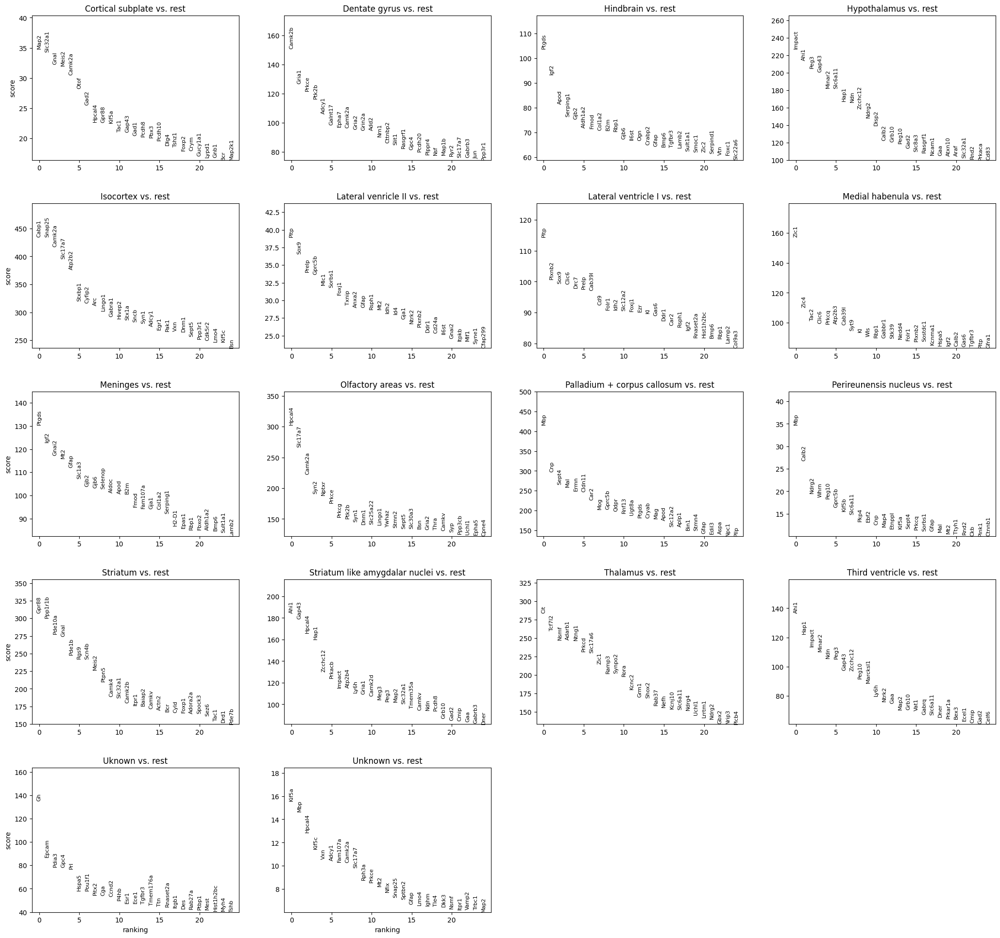

Cortical subplate
Map2 Slc32a1 Gnal Meis2 Camk2a Otof Gad2 Hpcal4 Gpr88 Kif5a
 
Dentate gyrus
Camk2b Gria1 Prkce Ptk2b Adcy1 Galnt17 Epha7 Camk2a Gria2 Grin2a
 
Hindbrain
Ptgds Igf2 Apod Serping1 Gjb2 Aldh1a2 Fmod Col1a2 B2m Rbp1
 
Hypothalamus
Impact Ahi1 Peg3 Gap43 Minar2 Slc6a11 Hap1 Ndn Zcchc12 Ndrg2
 
Isocortex
Cabp1 Snap25 Camk2a Slc17a7 Atp2b2 Stxbp1 Cyfip2 Arc Lingo1 Gabra1
 
Lateral venricle II
Pltp Sox9 Prelp Gprc5b Mlc1 Sorbs1 Foxj1 Txnip Anxa2 Gfap
 
Lateral ventricle I
Pltp Plxnb2 Sox9 Clic6 Drc7 Prelp Cab39l Cd9 Folr1 Idh2
 
Medial habenula
Zic1 Zic4 Tac2 Clic6 Prkcq Atp2b3 Cab39l Syt9 Kl Wls
 
Meninges
Ptgds Igf2 Gnai2 Mt2 Gfap Slc1a3 Gjb2 Gjb6 Selenop Aldoc
 
Olfactory areas
Hpcal4 Slc17a7 Camk2a Syn2 Nptxr Prkce Prkcg Ptk2b Syn1 Dnm1
 
Palladium + corpus callosum
Mbp Cnp Sept4 Mal Ermn Cldn11 Car2 Mog Gprc5b Qdpr
 
Perireunensis nucleus
Mbp Calb2 Ndrg2 Whrn Peg10 Gprc5b Kif5b Slc6a11 Pkp4 Ebf2
 
Striatum
Gpr88 Ppp1r1b Pde10a Gnal Pde1b Rgs9 Scn4b Meis2 Ptpn5 Camk4
 
St

In [95]:
sc.tl.rank_genes_groups(adata, groupby='compartment', method='t-test')
# See top 5 marker genes per cluster
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

marker_genes = pd.DataFrame({
    group: adata.uns['rank_genes_groups']['names'][group][:10]
    for group in adata.uns['rank_genes_groups']['names'].dtype.names
})
marker_genes.head()
#marker_genes.to_csv('../data/broad_markers_leiden0-5.csv')
for col in marker_genes.columns: 
    print(col)
    genes = marker_genes[col].tolist()
    print(" ".join(genes))
    print(' ')

In [96]:
mtDSB_genes = [
    "Hspa5", "Hspa9", "Hsph1",
    "Atf5", "Trib3", "Zbtb16", "Ddit3",
    "Cdkn1a", "Bcl2l1",
    "Sgk1", "Nmu", "Plin4", "Aldoa",
    "Serpina3n", "Mt2", "Gstp1",'Ldha'
]

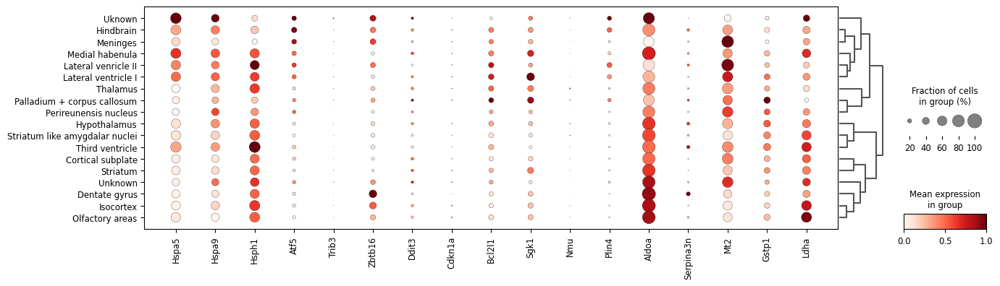

In [103]:
sc.pl.dotplot(
        adata,
        var_names=mtDSB_genes,
        groupby="compartment",
        standard_scale="var",
        #dot_max=0.5,
        #dot_min=0.05,
        color_map="Reds",
        
        dendrogram=True,
        figsize=(15, 4)
    )

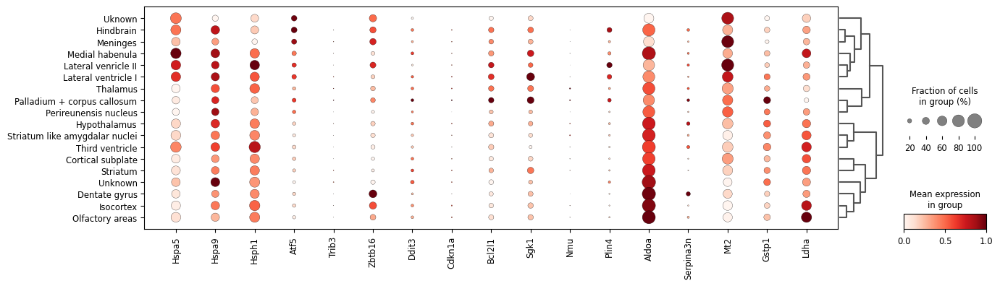

In [102]:
sc.pl.dotplot(
        adata[adata.obs.condition == 'mtDSB'],
        var_names=mtDSB_genes,
        groupby="compartment",
        standard_scale="var",
        #dot_max=0.5,
        #dot_min=0.05,
        color_map="Reds",
        
        dendrogram=True,
        figsize=(15, 4)
    )

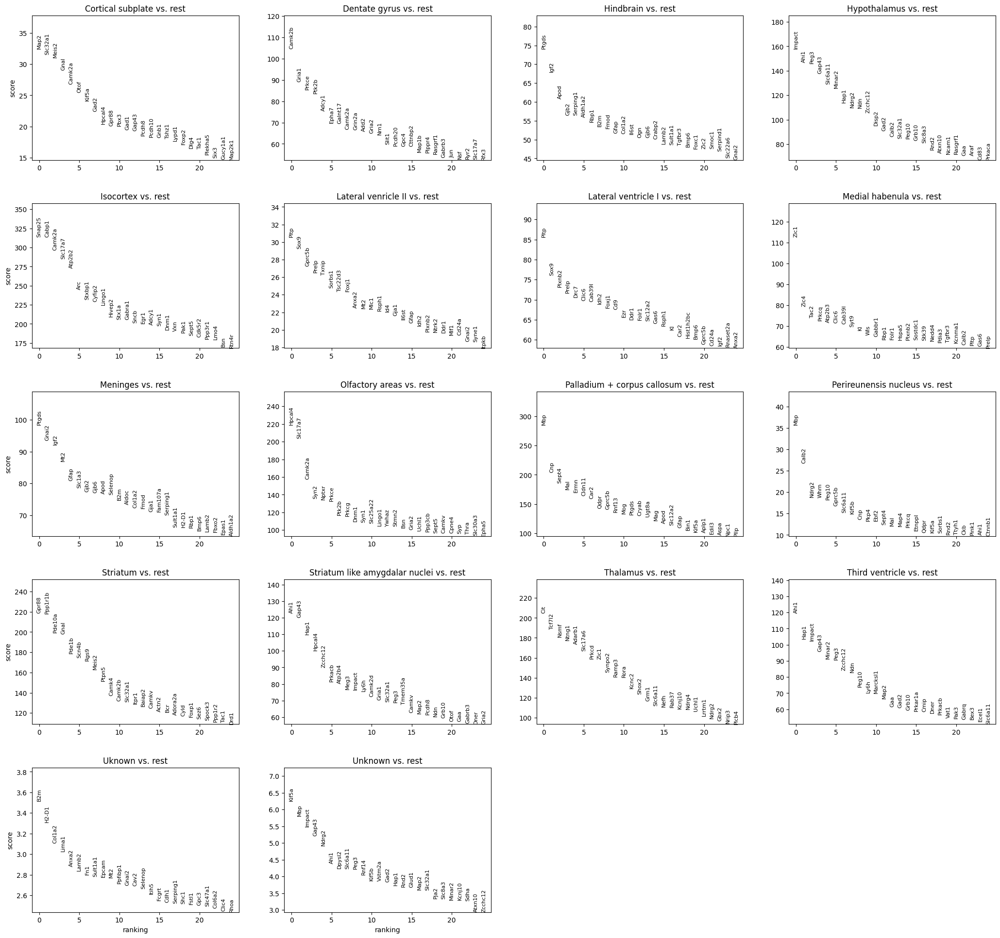

Cortical subplate
Map2 Slc32a1 Meis2 Gnal Camk2a Otof Kif5a Gad2 Hpcal4 Gpr88
 
Dentate gyrus
Camk2b Gria1 Prkce Ptk2b Adcy1 Epha7 Galnt17 Camk2a Grin2a Add2
 
Hindbrain
Ptgds Igf2 Apod Gjb2 Serping1 Aldh1a2 Rbp1 B2m Fmod Gfap
 
Hypothalamus
Impact Ahi1 Peg3 Gap43 Slc6a11 Minar2 Hap1 Ndrg2 Ndn Zcchc12
 
Isocortex
Snap25 Cabp1 Camk2a Slc17a7 Atp2b2 Arc Stxbp1 Cyfip2 Lingo1 Hivep2
 
Lateral venricle II
Pltp Sox9 Gprc5b Prelp Txnip Sorbs1 Tsc22d3 Foxj1 Anxa2 Mt2
 
Lateral ventricle I
Pltp Sox9 Plxnb2 Prelp Drc7 Clic6 Cab39l Idh2 Foxj1 Cd9
 
Medial habenula
Zic1 Zic4 Tac2 Prkcq Atp2b3 Clic6 Cab39l Syt9 Kl Wls
 
Meninges
Ptgds Gnai2 Igf2 Mt2 Gfap Slc1a3 Gjb2 Gjb6 Apod Selenop
 
Olfactory areas
Hpcal4 Slc17a7 Camk2a Syn2 Nptxr Prkce Ptk2b Prkcg Dnm1 Syn1
 
Palladium + corpus callosum
Mbp Cnp Sept4 Mal Ermn Cldn11 Car2 Qdpr Gprc5b Rnf13
 
Perireunensis nucleus
Mbp Calb2 Ndrg2 Whrn Peg10 Gprc5b Slc6a11 Kif5b Cnp Pkp4
 
Striatum
Gpr88 Ppp1r1b Pde10a Gnal Pde1b Scn4b Rgs9 Meis2 Ptpn5 Camk4
 
Str

In [105]:
adata_mTDSB = adata[adata.obs.condition == 'mtDSB']
sc.tl.rank_genes_groups(adata_mTDSB, groupby='compartment', method='t-test')
# See top 5 marker genes per cluster
sc.pl.rank_genes_groups(adata_mTDSB, n_genes=25, sharey=False)

marker_genes = pd.DataFrame({
    group: adata_mTDSB.uns['rank_genes_groups']['names'][group][:10]
    for group in adata_mTDSB.uns['rank_genes_groups']['names'].dtype.names
})
marker_genes.head()
#marker_genes.to_csv('../data/broad_markers_leiden0-5.csv')
for col in marker_genes.columns: 
    print(col)
    genes = marker_genes[col].tolist()
    print(" ".join(genes))
    print(' ')